# Component 3, Workflow 1: PP1 results and figures

This notebook reproduces every result and figure shown in the PP1 slides, from the code in this repository.

| Section | What it shows | Slide |
|---|---|---|
| 1 | Member 2's real CFD data and the automatic data checks | Methodology |
| 2 | Training and test data sizes (cross-validation by design) | Methodology |
| 3 | Accuracy: original vs augmented dataset, per model | Key functions & insights |
| 4 | The final drag model (model card) | Key functions & insights |
| 5 | Per-label physics checks of the synthetic labels | Design excellence |
| 6 | **Key function 1**: physics-informed labelling of a new shape | Live demo |
| 7 | **Key function 2**: fast drag prediction for a new shape | Live demo |
| 8 | The PP1 diagrams | Methodology, design excellence, feedback |
| 9 | (Optional) the full Workflow 1 run that produced the results in 3–5 | |

**Where the results come from.** `scripts/run_workflow1.py real` runs the whole Workflow 1 (cross-validation of every model, with and without augmentation, then the final model). It saves its results in `outputs/` and the trained model in `models/member2_sedan_pp1/`. Sections 3–5 read those saved results; section 9 can re-run everything (it takes a long time).

In [1]:
import json, os, sys, warnings
warnings.filterwarnings("ignore")
ROOT = os.path.abspath("..")
sys.path.insert(0, os.path.join(ROOT, "src"))
sys.path.insert(0, os.path.join(ROOT, "scripts"))
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
from component3 import config
%matplotlib inline
pd.set_option("display.width", 160)
TAG, SPEEDS, COUNTS = "member2_sedan_pp1", (40, 100), 1000   # 1 drag count = 0.001 Cd
print("data:", config.REAL_DATA_DIR)

data: D:\Research\J26-DS-315_Aero-Optimization-EV-Energy\component3_ml_backend\data\member2_sedan_pp1


## 1. Real CFD data (Member 2) and the automatic data checks
Every run must pass the data-contract checks before Workflow 1 uses it.

In [2]:
runs = pd.read_csv(os.path.join(config.REAL_DATA_DIR, "run_table.csv"))
print(f"{runs['design_id'].nunique()} shapes x {runs['speed_kmh'].nunique()} speeds = {len(runs)} CFD runs")
display(runs.head())

from component3.data.checker import check_dataset
checks = pd.DataFrame(check_dataset(config.REAL_DATA_DIR), columns=["check", "result", "detail"])
print(checks["result"].value_counts().to_string())
display(checks)

30 shapes x 2 speeds = 60 CFD runs


,design_id,speed_kmh,windshield_angle_deg,spoiler_angle_deg,boat_tail_angle_deg,hood_angle_deg,ground_clearance_mm,Cd,Cd_mean,Cd_std,...,remesh_diff_pct,map_cd_err_pct,map_p_err_cp,map_tau_err_cp,map_dist_mean_mm,map_dist_p99_mm,Cd_label,Cd_mean_se,Cd_se_neff,scenario
0,D000,100,28.00,10.00,15.00,10.00,150.00,0.348821,0.366758,0.012140,...,NaN,NaN,NaN,NaN,NaN,NaN,0.3668,0.00356,11.8,highway
1,D000,40,28.00,10.00,15.00,10.00,150.00,0.370790,0.370889,0.012251,...,NaN,NaN,NaN,NaN,NaN,NaN,0.3709,0.00425,10.9,urban
2,D002,100,22.52,14.33,19.75,5.32,183.52,0.403787,0.394745,0.010852,...,-2.3,-0.88,0.0128,0.00027,6.2,18.1,0.3947,0.00328,12.2,highway
3,D002,40,22.52,14.33,19.75,5.32,183.52,0.391796,0.390755,0.010499,...,NaN,NaN,NaN,NaN,NaN,NaN,0.3908,0.00282,12.5,urban
4,D003,100,25.54,10.66,13.46,10.16,162.82,0.378523,0.362621,0.009729,...,0.2,-1.18,0.0171,0.00008,5.2,16.8,0.3626,0.00300,11.2,highway


result
PASS    22
WARN     3


,check,result,detail
0,required files present,PASS,"run_table, design_table"
1,case.json present (optional),PASS,found
2,run_table required columns,PASS,14 columns found
3,run_table recommended columns,PASS,all present
4,speeds are 40 and 100 km/h,PASS,"found [40, 100]"
5,every design has both speeds,PASS,0 designs without both
6,every run's design is in design_table,PASS,
7,every planned design has been run,WARN,partial delivery: 30 of 70 designs run so far
8,baseline D000 present,PASS,
9,shape values agree between the two tables,PASS,max difference 0.00e+00


## 2. Training and test data sizes
Cross-validation by design: in each round some real shapes are hidden **at both speeds** and used only for testing. Synthetic shapes are used for training only.

In [3]:
%run ../scripts/show_data_split.py

=== Workflow 1 data sizes: member2_sedan_pp1 ===

1. Real CFD data (Member 2)
   30 designs x 2 speeds (40 km/h, 100 km/h) = 60 runs
   testable designs: 22  (the other 8 - baseline, extreme corners, low-confidence morphs - always train)

2. Cross-validation by design: 4 groups x 3 repeats = 12 folds
   each fold, a group of designs is hidden at BOTH speeds and used only as the test set

                             train (real)  train (synthetic)  test (real only)
   fold testing 5 designs          50 runs         2,369 rows          10 runs
   fold testing 6 designs          48 runs         2,369 rows          12 runs
   (synthetic rows: about this many per fold, after the per-label checks; they are labelled by a
    labeller fitted on that fold's training designs only)

3. Over all folds
   designs tested per fold: 6, 6, 5, 5, 6, 6, 5, 5, 6, 6, 5, 5
   every testable design is tested once per repeat: 22 designs x 2 speeds = 44 test runs per repeat, 132 test predictions in total

4. 

## 3. Accuracy: original vs augmented dataset
`*+real` = trained on the original dataset (real CFD only); `*+aug` = trained on the augmented dataset (real + physics-labelled shapes). Every error is measured on held-out **real** CFD shapes the model never saw.

In [4]:
oof = pd.concat([pd.read_csv(os.path.join(config.OUTPUTS_DIR, f"workflow1_{TAG}_{s}kmh_predictions.csv")) for s in SPEEDS])
rows = []
for model in ("xgboost", "random_forest", "ann_mlp"):
    for data, col in (("original", f"{model}+real"), ("augmented", f"{model}+aug")):
        err = (oof[col] - oof["cd"]).abs()
        rows.append({"model": model, "dataset": data, "error (drag counts)": err.mean() * COUNTS,
                     "error (%)": (err / oof["cd"]).mean() * 100})
table = pd.DataFrame(rows)
table["accuracy (%)"] = 100 - table["error (%)"]
print(f"{len(oof)} test predictions on held-out real CFD shapes")
display(table.round(2))
wide = table.pivot(index="model", columns="dataset", values="error (%)")
wide["error reduction"] = (1 - wide["augmented"] / wide["original"]).map("{:.0%}".format)
display(wide.round(2))

132 test predictions on held-out real CFD shapes


,model,dataset,error (drag counts),error (%),accuracy (%)
0,xgboost,original,18.25,5.12,94.88
1,xgboost,augmented,9.26,2.64,97.36
2,random_forest,original,16.08,4.50,95.50
3,random_forest,augmented,9.91,2.81,97.19
4,ann_mlp,original,10.22,2.86,97.14
5,ann_mlp,augmented,9.36,2.66,97.34


dataset,augmented,original,error reduction
model,,,
ann_mlp,2.66,2.86,7%
random_forest,2.81,4.50,37%
xgboost,2.64,5.12,48%


In [5]:
import make_pp1_figures as figs
fig = figs.fig_original_vs_augmented()   # the chart on the slide (pp1_fig6_original_vs_augmented.png)
plt.show()

In [6]:
fig = figs.fig_model_errors()   # every candidate at each speed (pp1_fig1_model_errors.png)
plt.show()

## 4. The final drag model
The lowest cross-validated error wins and is retrained on all data. Its details are saved in the model card.

In [7]:
card = json.load(open(os.path.join(config.MODELS_DIR, TAG, "model_card.json")))
print("chosen model     :", card["drag_model"], "(augmentation used)" if card["uses_augmentation"] else "")
print("inputs           :", card["inputs"])
print("training data    :", sum(card["n_designs"].values()), "real CFD runs +",
      sum(card["synthetic_kept_per_speed"].values()), "checked synthetic shapes")
for s, e in card["cd_error_by_speed"].items():
    print(f"expected error   : {e['mae'] * COUNTS:.1f} drag counts at {s} km/h")

chosen model     : xgboost+aug (augmentation used)
inputs           : ['windshield_angle_deg', 'spoiler_angle_deg', 'boat_tail_angle_deg', 'hood_angle_deg', 'ground_clearance_mm', 'speed_kmh']
training data    : 60 real CFD runs + 2395 checked synthetic shapes
expected error   : 9.6 drag counts at 40 km/h
expected error   : 8.9 drag counts at 100 km/h


## 5. Per-label physics checks
Every synthetic label must pass four checks; labels that fail are removed before training.

In [8]:
for s in SPEEDS:
    lab = pd.read_csv(os.path.join(config.OUTPUTS_DIR, f"workflow1_{TAG}_{s}kmh_synthetic_labels.csv"))
    print(f"{s} km/h: {lab['keep'].sum()} of {len(lab)} labels kept ({lab['keep'].mean():.1%})")
    print("   failed: " + ", ".join(f"{c} {(~lab[c]).sum()}" for c in
          ("cp_below_stagnation", "pressure_drag_positive", "cd_in_range", "in_validated_region")))
display(lab.head())

40 km/h: 1196 of 1200 labels kept (99.7%)
   failed: cp_below_stagnation 0, pressure_drag_positive 0, cd_in_range 4, in_validated_region 0
100 km/h: 1199 of 1200 labels kept (99.9%)
   failed: cp_below_stagnation 0, pressure_drag_positive 0, cd_in_range 1, in_validated_region 0


,windshield_angle_deg,spoiler_angle_deg,boat_tail_angle_deg,hood_angle_deg,ground_clearance_mm,cd_label,sigma_raw,sigma_calibrated,distance_to_real,in_validated_region,max_cp,cp_below_stagnation,pressure_drag,pressure_drag_positive,cd_in_range,keep
0,22.492260,19.509352,19.469023,6.502522,153.593722,0.407371,0.002251,0.010138,0.470303,True,0.976029,True,0.318078,True,True,True
1,28.160244,11.570648,11.536899,7.923932,184.569974,0.385685,0.001605,0.009598,0.236429,True,0.977005,True,0.352180,True,True,True
2,28.186292,18.217887,9.872602,6.243144,124.703772,0.405177,0.001860,0.009793,0.263201,True,0.977435,True,0.371019,True,True,True
3,29.597728,12.274090,20.932270,6.076436,118.691222,0.393262,0.001701,0.009669,0.495609,True,0.977419,True,0.376559,True,True,True
4,33.552419,5.094091,8.100488,7.275891,149.614774,0.350737,0.002204,0.010093,0.461415,True,0.976530,True,0.360703,True,True,True


## 6. Key function 1: physics-informed labelling with per-label validation
A new shape gets a Cd label from the rebuilt surface pressure, with its uncertainty, and must pass the four checks. (About 45 s: the labeller is built from the real CFD first.)

In [9]:
%run ../scripts/label_shape.py 26 5 12 12 140 --speed 100

=== Physics-informed label for a new shape at 100 km/h ===
   windshield_angle_deg      26.00
   spoiler_angle_deg          5.00
   boat_tail_angle_deg       12.00
   hood_angle_deg            12.00
   ground_clearance_mm      140.00



1. Labeller built on 30 real CFD shapes: 2 POD pressure patterns + Gaussian Process (per_mode), chosen by cross-validation  [34.9 s]
2. Label: rebuilt the surface pressure from the patterns and integrated it over the car
   Cd = 0.3309 +/- 10 drag counts (uncertainty calibrated on held-out real CFD)
3. Per-label physics checks:
   [PASS] pressure never above the stagnation limit (max Cp 0.98 <= 1.0)
   [PASS] pressure drag is positive (air pushes the car backwards)
   [PASS] Cd inside the real CFD range (0.295 - 0.437)
   [PASS] shape inside the validated region (distance to nearest real shape 0.41 <= 0.68)

=> label KEPT: it may be used for training


## 7. Key function 2: fast drag prediction for a new shape
The final model predicts Cd and frontal area in milliseconds instead of hours of CFD.

In [10]:
%run ../scripts/predict_shape.py 26 5 12 12 140 --speed 100

=== Drag prediction with xgboost+aug (trained on 60 real CFD runs + 2,395 checked physics-labelled synthetic shapes) ===
Shape:
   windshield_angle_deg      26.00
   spoiler_angle_deg          5.00
   boat_tail_angle_deg       12.00
   hood_angle_deg            12.00
   ground_clearance_mm      140.00

At 100 km/h: Cd = 0.3305 (expected error about +/- 9 drag counts)
   frontal area A = 2.1975 m2,  drag area Cd x A = 0.7262 m2,  prediction time 11.8 ms

Compared with the baseline sedan at 100 km/h: -37.4 drag counts (-10.2%)

(model loaded in 34 ms; one CFD run of a new shape takes hours)


## 8. The PP1 diagrams
Drawn by `scripts/make_pp1_diagrams.py`.

wrote D:\Research\J26-DS-315_Aero-Optimization-EV-Energy\component3_ml_backend\outputs\figures\pp1_component3_architecture.png


wrote D:\Research\J26-DS-315_Aero-Optimization-EV-Energy\component3_ml_backend\outputs\figures\pp1_workflow1_methodology.png


wrote D:\Research\J26-DS-315_Aero-Optimization-EV-Energy\component3_ml_backend\outputs\figures\pp1_design_excellence.png


wrote D:\Research\J26-DS-315_Aero-Optimization-EV-Energy\component3_ml_backend\outputs\figures\pp1_user_feedback.png


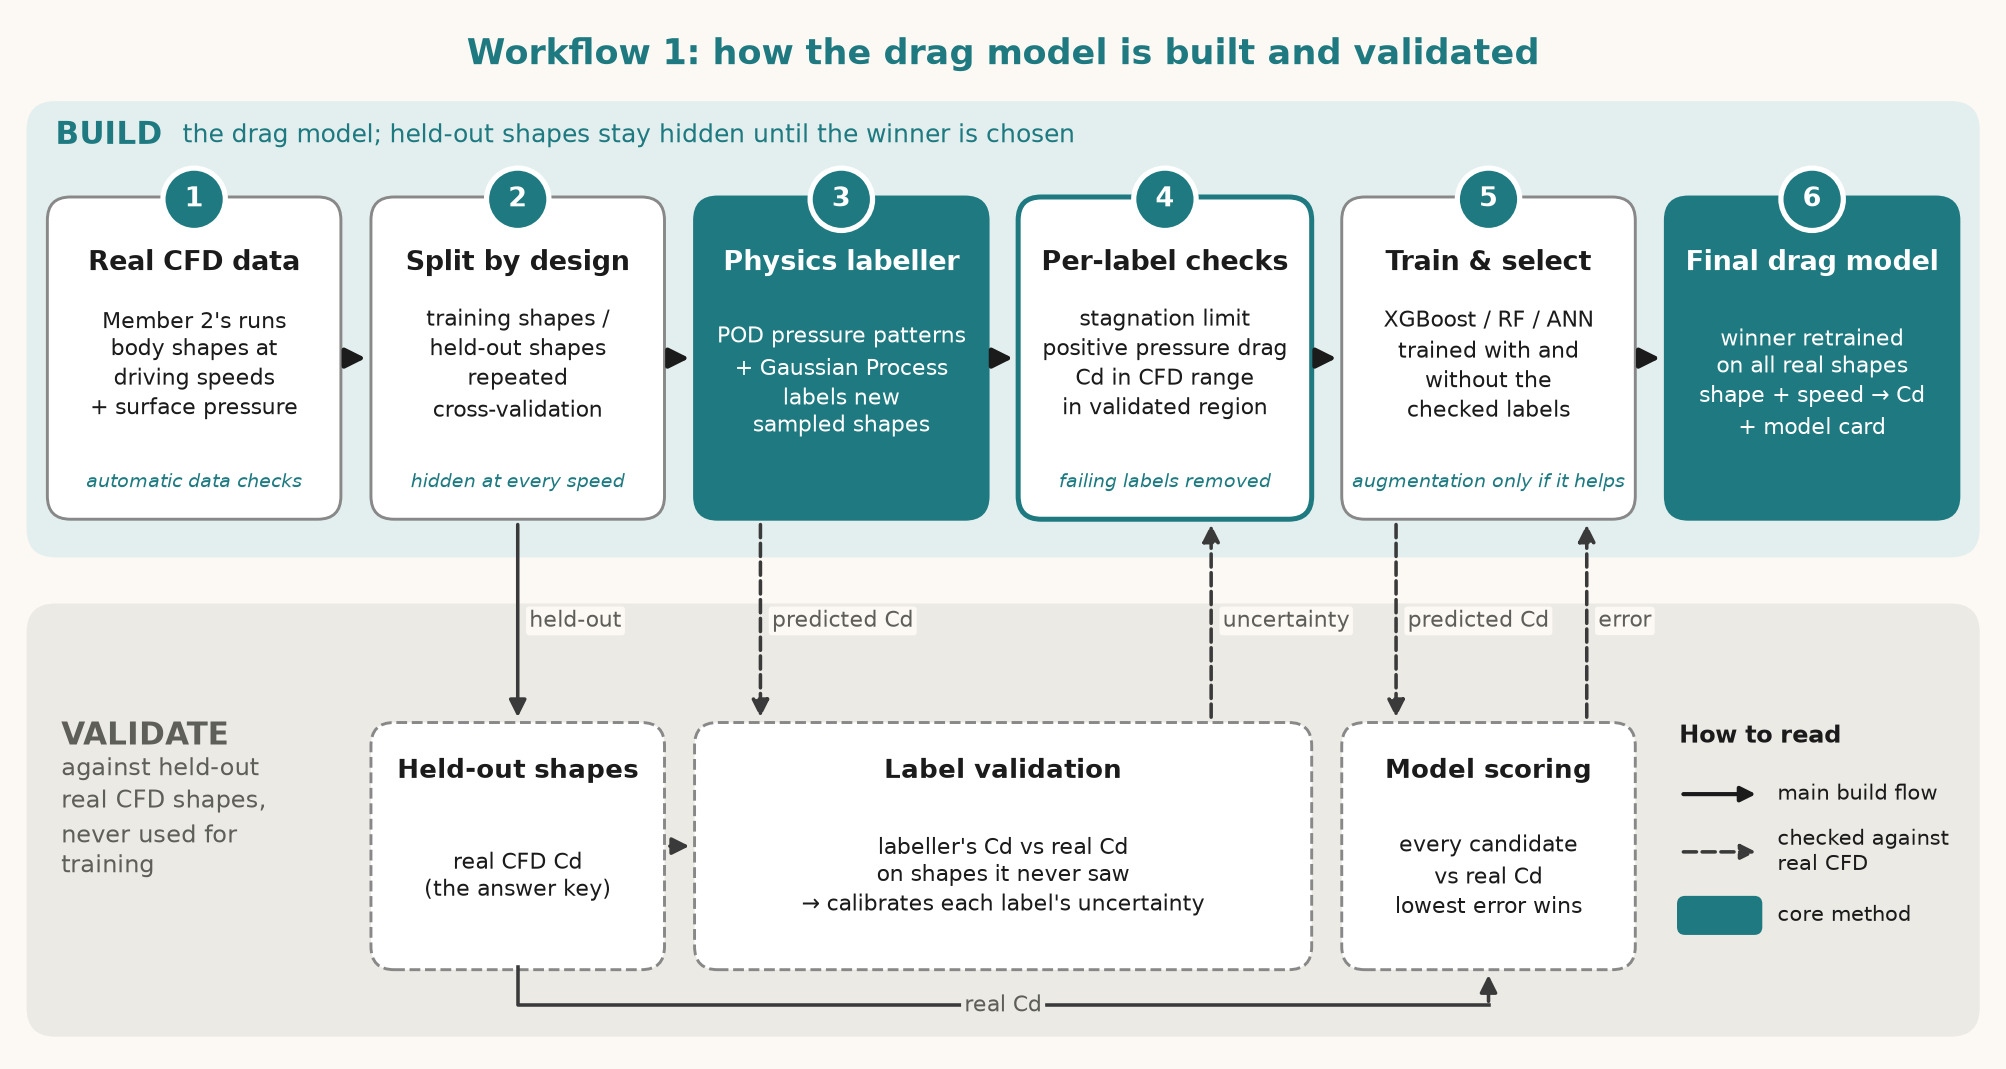

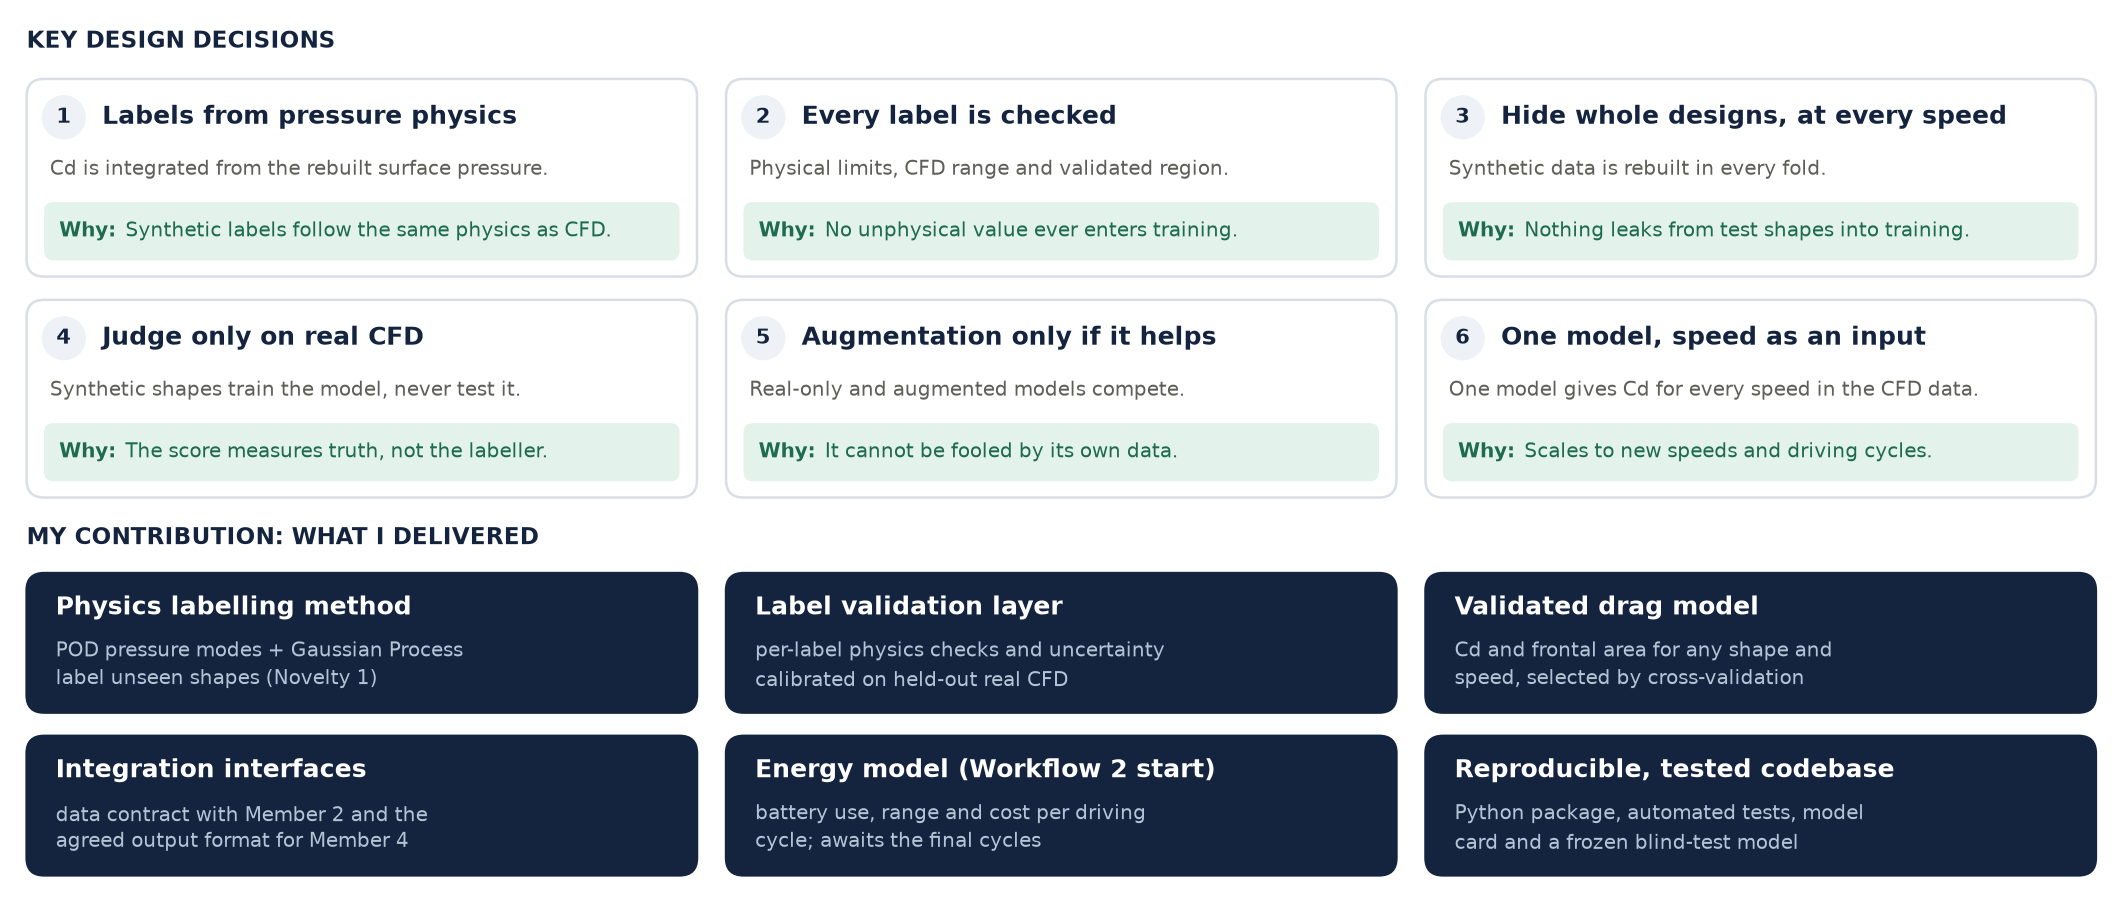

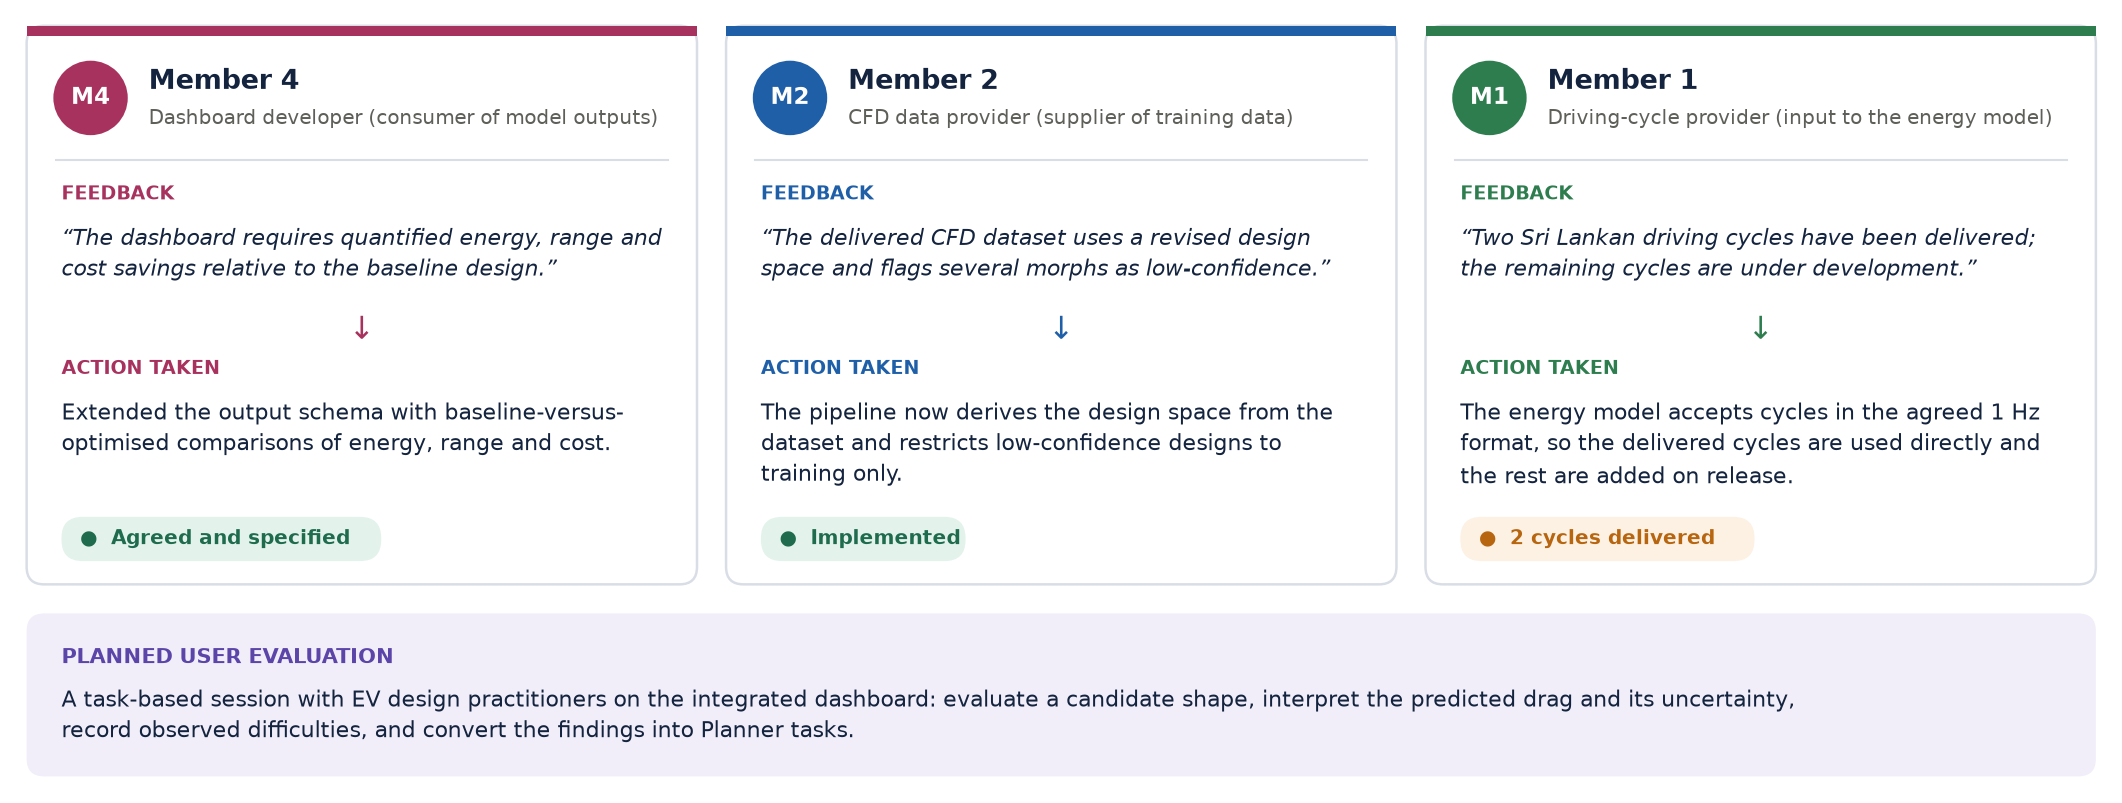

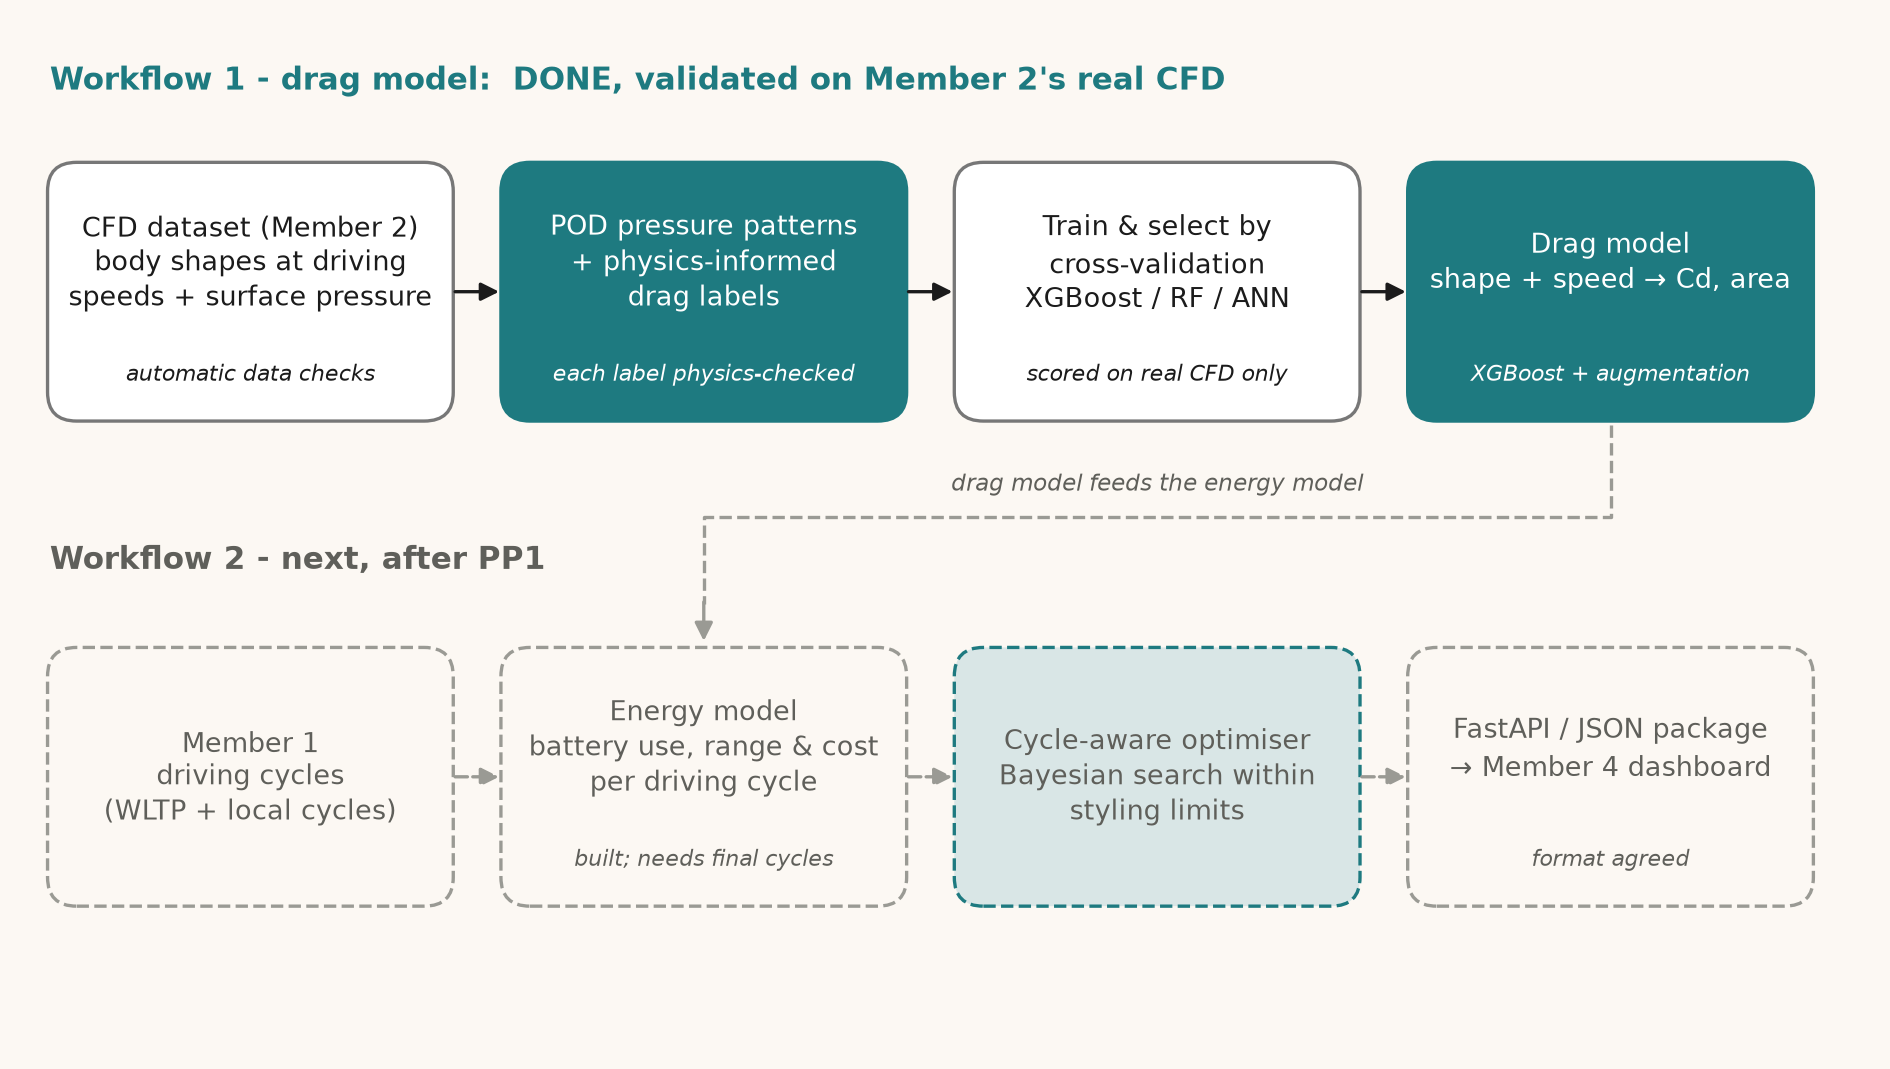

In [11]:
import make_pp1_diagrams as diagrams
diagrams.main()
for name in ("pp1_workflow1_methodology", "pp1_design_excellence", "pp1_user_feedback", "pp1_component3_architecture"):
    display(Image(os.path.join(config.OUTPUTS_DIR, "figures", f"{name}.png")))

## 9. (Optional) Re-run the whole of Workflow 1
This is the run that produced the results in sections 3–5: data check → POD → cross-validation of every model with and without augmentation → final model. It takes a long time, so it is switched off. Set `RUN_FULL = True` to run it. The saved log of the run is `outputs/logs/workflow1_member2_sedan_pp1_combined.txt`.

In [12]:
RUN_FULL = False
if RUN_FULL:
    %run ../scripts/run_workflow1.py real
else:
    print(open(os.path.join(config.OUTPUTS_DIR, "logs", "workflow1_member2_sedan_pp1_combined.txt")).read()[-3500:])

ce per repeat, hidden at every speed
   running 12 folds (2 parallel workers)
   22 designs can be tested
   labeller chosen inside the folds, 40 km/h: per_mode+ridge, 15 patterns x1, per_mode+ridge, 2 patterns x3, per_mode+ridge, 4 patterns x1, shared+ridge, 2 patterns x4, shared+ridge, 4 patterns x2, shared+ridge, 6 patterns x1
   labeller chosen inside the folds, 100 km/h: per_mode+ridge, 10 patterns x1, per_mode+ridge, 2 patterns x7, per_mode+ridge, 4 patterns x1, shared+ridge, 2 patterns x2, shared+ridge, 4 patterns x1

5. Results on REAL designs only, drag counts (mean over repeats +/- spread, worst design):
   --- 40 km/h
   helper labels (label check)         9.8 +/-  1.6   worst  30.9
   xgboost        with augmentation    9.6 +/-  1.3   real only   18.3 +/-  2.2   (augmentation better in 3/3 repeats)
   random_forest  with augmentation   10.3 +/-  1.4   real only   16.3 +/-  2.3   (augmentation better in 3/3 repeats)
   ann_mlp        with augmentation    9.9 +/-  1.9   real 